<a href="https://colab.research.google.com/github/knight19720208ui/AI/blob/main/3_Refuerzo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje por Refuerzo: 3 Ejemplos Prácticos en Python

Cuaderno didáctico para Google Colab. Cubre los **3 algoritmos de aprendizaje por refuerzo más representativos**.

| # | Algoritmo | Tipo | Entorno |
|---|-----------|------|---------|
| 1 | Q-Learning | Off-policy | Grid world 5x5 |
| 2 | SARSA | On-policy | Mismo grid world 5x5 |
| 3 | Multi-Armed Bandit (epsilon-greedy) | Exploración/explotación | 4 máquinas tragamonedas |

## Por qué solo Python puro

scikit-learn **no cubre** aprendizaje por refuerzo. Esta familia requiere bibliotecas especializadas (Gymnasium, Stable-Baselines3) que son más avanzadas. Aquí implementamos los algoritmos desde cero para que los estudiantes entiendan la intuición.


## Configuración inicial

Ejecuten la siguiente celda **antes de empezar**. Instala las librerías necesarias y carga todos los imports que se usarán a lo largo del cuaderno:
- **numpy**: cálculo numérico, tablas Q y simulación estocástica.
- **matplotlib** + **matplotlib.animation**: gráficas estáticas y animaciones del agente.
- **plotly**: gráficas interactivas para curvas de aprendizaje.
- **pandas**: manipulación de datos para graficar.
- **IPython.display**: para mostrar animaciones dentro del cuaderno.


In [2]:
# === Instalación de dependencias ===
# En Colab la mayoría ya están instaladas; esto es por seguridad
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "numpy", "matplotlib", "plotly", "pandas"])

# === Imports globales ===
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as mpatches
from matplotlib import rc
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from IPython.display import HTML, display
import warnings
warnings.filterwarnings('ignore')

# Configuración de matplotlib para animaciones en Colab/Jupyter
rc('animation', html='jshtml')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

# Reproducibilidad
np.random.seed(42)

# Verificación
print("Entorno listo. Versiones:")
print(f"  NumPy:       {np.__version__}")
print(f"  Pandas:      {pd.__version__}")
print(f"  Matplotlib:  {__import__('matplotlib').__version__}")
print(f"  Plotly:      {__import__('plotly').__version__}")


Entorno listo. Versiones:
  NumPy:       2.4.6
  Pandas:      2.2.3
  Matplotlib:  3.10.0
  Plotly:      5.24.1


# Glosario de conceptos de aprendizaje por refuerzo

Antes de los ejemplos, definimos los términos clave. Cada uno aparece **una sola vez** aquí.

- **Agente**: la entidad que toma decisiones. En nuestros ejemplos: un robot, un jugador de casino, etc.

- **Entorno (environment)**: el mundo con el que el agente interactúa. Define las reglas: estados posibles, acciones permitidas, recompensas.

- **Estado ($s$)**: la situación actual del agente en el entorno. Por ejemplo, una posición (fila, columna) en un grid.

- **Acción ($a$)**: lo que el agente puede hacer en cada estado. Por ejemplo: moverse arriba/abajo/izquierda/derecha.

- **Recompensa ($r$)**: señal numérica que recibe el agente al tomar una acción. Puede ser positiva (llegar a la meta) o negativa (chocar con un obstáculo). Es la única guía que tiene el agente para aprender.

- **Política ($\pi$)**: función que decide qué acción tomar en cada estado. Puede ser determinista ($\pi(s) = a$) o estocástica ($\pi(a|s)$ = probabilidad).

- **Función de valor $Q(s, a)$**: estimación de la recompensa acumulada esperada si el agente toma la acción $a$ en el estado $s$ y luego sigue su política actual. Es lo que aprenden Q-Learning y SARSA.

- **Factor de descuento ($\gamma$)**: número en $[0, 1]$ que descuenta las recompensas futuras. $\gamma=0$ => el agente solo mira la recompensa inmediata; $\gamma=1$ => valora igual el presente y el futuro. Típicamente $\gamma \approx 0.9-0.99$.

- **Learning rate ($\alpha$)**: qué tan rápido se actualiza la tabla Q. $\alpha=0$ => no aprende nada nuevo; $\alpha=1$ => reemplaza completamente el valor anterior. Típicamente $\alpha \approx 0.1-0.5$.

- **Exploración vs. explotación**: dilema central. El agente puede **explotar** lo que ya sabe (la mejor acción según Q) o **explorar** acciones nuevas por si resultan mejores. La estrategia **epsilon-greedy** explora con probabilidad $\epsilon$ y explota con probabilidad $1-\epsilon$.

- **Off-policy vs. on-policy**:
  - **Off-policy** (Q-Learning): aprende del mejor movimiento posible, aunque después explore aleatoriamente. Más agresivo.
  - **On-policy** (SARSA): aprende de lo que realmente hace (incluida la exploración). Más conservador.

- **Episodio**: una secuencia completa de interacciones que termina (llegar a la meta, morir, agotar pasos, etc.). El entrenamiento consta de muchos episodios.

- **Convergencia**: cuando los valores Q dejan de cambiar significativamente entre episodios; el agente ya "sabe" qué hacer.

- **Recompensa acumulada (return)**: suma de las recompensas a lo largo de un episodio, posiblemente descontadas por $\gamma$. Es la cantidad que el agente trata de maximizar.

- **Grid world**: entorno clásico de juguete donde el agente se mueve en una cuadrícula. Cada celda es un estado; las acciones son los 4 movimientos. Hay obstáculos y una meta.


# [PY] 3.1 Q-Learning -- Python puro

## Ejemplo

Supongan que un robot de limpieza debe navegar una habitación 5x5 representada como grid, llegar a la estación de carga (meta) evitando muebles (obstáculos). No sabe dónde está la meta; la descubre probando.

## Qué aprenderán

- Cómo se construye y actualiza una **tabla Q** de dimensiones $|S| \times |A|$.
- La estrategia **epsilon-greedy**: la mayoría del tiempo elige la mejor acción, pero a veces explora al azar.
- Cómo leer la curva de aprendizaje: la recompensa por episodio sube conforme el agente aprende el camino óptimo.
- Que Q-Learning es **off-policy**: aprende del máximo Q del siguiente estado, aunque después explore.

## Idea matemática

$$Q(s, a) \leftarrow Q(s, a) + \alpha [r + \gamma \max_{a'} Q(s', a') - Q(s, a)]$$

Donde:
- $r$ = recompensa inmediata recibida
- $s'$ = nuevo estado tras tomar la acción $a$
- $\max_{a'} Q(s', a')$ = mejor valor Q posible en $s'$

Esta fórmula se llama **actualización de Bellman** y refleja que el agente aprende considerando el mejor escenario futuro posible.


In [3]:
# === 3.1 Q-LEARNING -- Python puro ===
np.random.seed(42)

# Grid world 5x5
# 0 = libre, 1 = obstáculo, 2 = meta
GRID = np.array([
    [0, 0, 0, 1, 0],
    [0, 1, 0, 1, 0],
    [0, 1, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 2],
])
ROWS, COLS = GRID.shape
START = (0, 0)
GOAL = (4, 4)
ACTIONS = ['arriba', 'abajo', 'izq', 'der']  # 0: arriba, 1: abajo, 2: izq, 3: der

def step(state, action):
    r, c = state
    if action == 0: r = max(0, r-1)
    elif action == 1: r = min(ROWS-1, r+1)
    elif action == 2: c = max(0, c-1)
    elif action == 3: c = min(COLS-1, c+1)
    if GRID[r, c] == 1:  # obstáculo: quedarse quieto
        return state, -1
    if (r, c) == GOAL:
        return (r, c), 10
    return (r, c), -0.1

# Tabla Q
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha = 0.5    # learning rate
gamma = 0.95   # factor de descuento
epsilon = 0.3   # exploración
episodes = 200

episode_rewards = []
episode_paths = []  # guardamos algunos trayectos para animar
sample_episodes = [0, 20, 50, 100, 199]  # grabar estos

for ep in range(episodes):
    s = START
    path = [s]
    total_r = 0
    for _ in range(100):  # máximo 100 pasos
        # epsilon-greedy
        if np.random.rand() < epsilon:
            a = np.random.randint(len(ACTIONS))
        else:
            a = np.argmax(Q[s[0], s[1]])
        s_new, r = step(s, a)
        # Actualización Q-Learning (off-policy: usa max del siguiente estado)
        best_next = np.max(Q[s_new[0], s_new[1]])
        Q[s[0], s[1], a] += alpha * (r + gamma * best_next - Q[s[0], s[1], a])
        s = s_new
        path.append(s)
        total_r += r
        if s == GOAL:
            break
    episode_rewards.append(total_r)
    if ep in sample_episodes:
        episode_paths.append((ep, path))

print(f"Recompensa final: {episode_rewards[-1]:.2f}")
print(f"Episodios exitosos en últimos 20: {sum(r > 5 for r in episode_rewards[-20:])}/20")
print(f"Q-value en estado inicial: {Q[0, 0].round(2)}")
print(f"Mejor acción inicial: {ACTIONS[np.argmax(Q[0, 0])]}")


Recompensa final: 6.10
Episodios exitosos en últimos 20: 19/20
Q-value en estado inicial: [5.96 5.5  5.96 6.38]
Mejor acción inicial: der


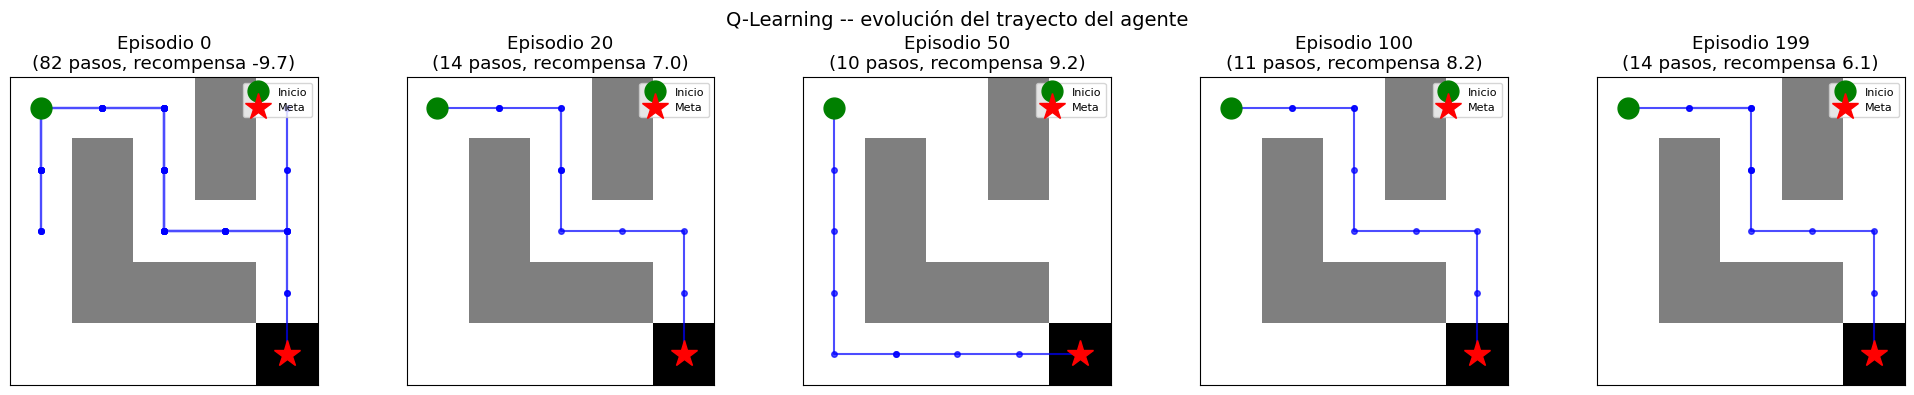

In [4]:
# === GRÁFICA: trayectorias del agente en distintos episodios ===
fig, axes = plt.subplots(1, len(episode_paths), figsize=(4*len(episode_paths), 4))
if len(episode_paths) == 1: axes = [axes]

for ax, (ep, path) in zip(axes, episode_paths):
    ax.imshow(GRID, cmap='gray_r')
    # Dibujar camino
    path_arr = np.array(path)
    ax.plot(path_arr[:, 1], path_arr[:, 0], 'b.-', markersize=8, alpha=0.7)
    ax.plot(path_arr[0, 1], path_arr[0, 0], 'go', markersize=15, label='Inicio')
    ax.plot(GOAL[1], GOAL[0], 'r*', markersize=20, label='Meta')
    ax.set_title(f'Episodio {ep}\n({len(path)} pasos, recompensa {episode_rewards[ep]:.1f})')
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=8, loc='upper right')
plt.suptitle('Q-Learning -- evolución del trayecto del agente', fontsize=14)
plt.tight_layout(); plt.show()

# Curva de aprendizaje
fig2 = px.line(x=list(range(episodes)), y=episode_rewards,
               title='Q-Learning -- recompensa por episodio',
               labels={'x': 'Episodio', 'y': 'Recompensa total'},
               template='plotly_white')
fig2.show()


# [PY] 3.2 SARSA -- Python puro

## Contexto del ejemplo

Mismo grid world que en el ejemplo 3.1, pero ahora usamos SARSA para comparar cómo aprende el agente. La diferencia sutil en la fórmula genera comportamientos distintos cuando hay penalizaciones (como los obstáculos).

## Qué aprenderán

- La diferencia clave con Q-Learning: SARSA usa la acción **realmente tomada** en $s'$, no el máximo teórico.
- Que SARSA es más conservador: si hay riesgos cerca del camino óptimo, SARSA los evita (porque aprende considerando la exploración).
- Que ambos convergen a la misma política si no hay penalizaciones, pero divergen cuando las hay.

## Idea matemática

$$Q(s, a) \leftarrow Q(s, a) + \alpha [r + \gamma Q(s', a') - Q(s, a)]$$

Donde $a'$ es la acción realmente tomada en $s'$ (seguramente con epsilon-greedy). Compárense con la fórmula de Q-Learning del ejemplo 3.1: la única diferencia es $\max_{a'} Q(s', a')$ vs $Q(s', a')$.

## Mnemotecnia

El nombre **SARSA** viene de la secuencia que usa: **S**tate, **A**ction, **R**eward, **S**tate, **A**ction. Refleja que se necesitan los 5 elementos para actualizar la tabla.


In [5]:
# === 3.2 SARSA -- Python puro ===
np.random.seed(42)

# Reutilizamos GRID, START, GOAL, ACTIONS, step del ejemplo anterior
Q_sarsa = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma, epsilon = 0.5, 0.95, 0.3
episodes = 200

episode_rewards_sarsa = []
episode_paths_sarsa = []

for ep in range(episodes):
    s = START
    # epsilon-greedy para acción inicial
    if np.random.rand() < epsilon: a = np.random.randint(len(ACTIONS))
    else: a = np.argmax(Q_sarsa[s[0], s[1]])
    path = [s]
    total_r = 0
    for _ in range(100):
        s_new, r = step(s, a)
        # epsilon-greedy para acción siguiente
        if np.random.rand() < epsilon: a_new = np.random.randint(len(ACTIONS))
        else: a_new = np.argmax(Q_sarsa[s_new[0], s_new[1]])
        # SARSA: usa a_new (no max)
        Q_sarsa[s[0], s[1], a] += alpha * (r + gamma * Q_sarsa[s_new[0], s_new[1], a_new] - Q_sarsa[s[0], s[1], a])
        s, a = s_new, a_new
        path.append(s)
        total_r += r
        if s == GOAL: break
    episode_rewards_sarsa.append(total_r)
    if ep in sample_episodes:
        episode_paths_sarsa.append((ep, path))

print(f"Recompensa final SARSA: {episode_rewards_sarsa[-1]:.2f}")
print(f"Recompensa final Q-Learning (ejemplo anterior): {episode_rewards[-1]:.2f}")
print(f"Episodios exitosos SARSA en últimos 20: {sum(r > 5 for r in episode_rewards_sarsa[-20:])}/20")


Recompensa final SARSA: 8.00
Recompensa final Q-Learning (ejemplo anterior): 6.10
Episodios exitosos SARSA en últimos 20: 18/20


In [6]:
# === GRÁFICA: comparación Q-Learning vs SARSA (interactiva) ===
df_cmp = pd.DataFrame({
    'Episodio': list(range(episodes)) * 2,
    'Recompensa': episode_rewards + episode_rewards_sarsa,
    'Algoritmo': ['Q-Learning']*episodes + ['SARSA']*episodes
})

# Suavizado con media móvil
window = 10
df_cmp['Recompensa suavizada'] = df_cmp.groupby('Algoritmo')['Recompensa'].transform(
    lambda x: x.rolling(window, min_periods=1).mean())

fig = px.line(df_cmp, x='Episodio', y='Recompensa suavizada', color='Algoritmo',
              title=f'Q-Learning vs SARSA -- recompensa suavizada (media móvil {window})',
              template='plotly_white', color_discrete_map={'Q-Learning': '#1f77b4', 'SARSA': '#ff7f0e'})
fig.show()


# [PY] 3.3 Multi-Armed Bandit (epsilon-greedy) -- Python puro

## Contexto del ejemplo

Supongan que están en un casino con 4 máquinas tragamonedas. Cada una tiene una probabilidad de pago desconocida. Tienen 1.000 monedas y quieren maximizar sus ganancias. El dilema: probar la que mejor ha pagado hasta ahora (explotar) o probar otra por si resulta mejor (explorar).

## Qué aprenderán

- El **dilema exploración-explotación** en su forma más pura.
- La estrategia **epsilon-greedy**: con probabilidad epsilon explora, con 1-epsilon explota.
- Cómo el agente converge a identificar la mejor máquina y deja de explorar las demás.
- Que la **recompensa media** se acerca al valor óptimo teórico pero no llega exactamente (por la exploración residual).

## Idea matemática

Para cada brazo $k$ mantenemos una estimación $Q_k$ del valor medio observado:

- Actualización incremental: $Q_k \leftarrow Q_k + \frac{1}{N_k}(r - Q_k)$, donde $N_k$ = veces que se eligió $k$.

Política epsilon-greedy:
- Con probabilidad $\epsilon$: $a \sim \text{Uniforme}(1, ..., K)$ (explorar)
- Con probabilidad $1-\epsilon$: $a = \arg\max_k Q_k$ (explotar)

Este problema, aparentemente simple, es la base de muchos sistemas modernos: recomendación de contenido, A/B testing, selección de anuncios, etc.


In [7]:
# === 3.3 MULTI-ARMED BANDIT -- Python puro ===
np.random.seed(42)

# 4 brazos con probabilidades reales desconocidas para el agente
TRUE_PROBS = [0.2, 0.5, 0.75, 0.9]
K = len(TRUE_PROBS)
n_steps = 1000
epsilon = 0.1

# Estimaciones Q y conteo de veces elegido cada brazo
Q = np.zeros(K)
N = np.zeros(K)

action_history = []
reward_history = []
Q_history = []  # para animar la evolución de las estimaciones

for t in range(n_steps):
    # epsilon-greedy
    if np.random.rand() < epsilon:
        a = np.random.randint(K)
    else:
        a = np.argmax(Q)
    # Recompensa: 1 con probabilidad TRUE_PROBS[a]
    r = 1.0 if np.random.rand() < TRUE_PROBS[a] else 0.0
    N[a] += 1
    Q[a] += (r - Q[a]) / N[a]  # media incremental
    action_history.append(a)
    reward_history.append(r)
    Q_history.append(Q.copy())

print(f"Probabilidades reales: {TRUE_PROBS}")
print(f"Estimaciones finales: {Q.round(3)}")
print(f"Veces elegido cada brazo: {N.astype(int)}")
print(f"Recompensa media: {np.mean(reward_history):.3f} (óptimo teórico: {max(TRUE_PROBS):.3f})")


Probabilidades reales: [0.2, 0.5, 0.75, 0.9]
Estimaciones finales: [0.2   0.367 0.742 0.902]
Veces elegido cada brazo: [ 30  30  31 909]
Recompensa media: 0.860 (óptimo teórico: 0.900)


In [8]:
# === GRÁFICA: animación de la evolución de las estimaciones Q ===
fig, ax = plt.subplots(figsize=(10, 6))

Q_arr = np.array(Q_history)
frames_to_show = list(range(0, n_steps, 20))

def update(frame_idx):
    ax.clear()
    t = frames_to_show[frame_idx]
    qs = Q_arr[t]
    colors = ['green' if a == np.argmax(qs) else 'gray' for a in range(K)]
    bars = ax.bar(range(K), qs, color=colors, edgecolor='black')
    # Líneas de probabilidad real
    for k, p in enumerate(TRUE_PROBS):
        ax.plot([k-0.4, k+0.4], [p, p], 'r-', lw=2)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(range(K))
    ax.set_xticklabels([f'Brazo {k}\n(p={p:.2f})' for k, p in enumerate(TRUE_PROBS)])
    ax.set_ylabel('Estimación Q')
    ax.set_title(f'Multi-Armed Bandit (epsilon-greedy) -- paso {t}/{n_steps}\nRecompensa acumulada: {sum(reward_history[:t]):.0f}')
    ax.grid(alpha=0.3, axis='y')
    # Leyenda
    green_patch = mpatches.Patch(color='green', label='Brazo preferido')
    gray_patch = mpatches.Patch(color='gray', label='Otros')
    red_line = mpatches.Patch(color='red', label='Prob. real')
    ax.legend(handles=[green_patch, gray_patch, red_line], loc='upper left')

anim = animation.FuncAnimation(fig, update, frames=len(frames_to_show),
                               interval=120, blit=False)
plt.close()
HTML(anim.to_jshtml())


In [9]:
# === GRÁFICA adicional: frecuencia de elección de cada brazo a lo largo del tiempo ===
# Calculamos la fracción de veces que se eligió cada brazo en ventanas de 50 pasos
window = 50
freq_history = np.zeros((n_steps - window, K))
for t in range(window, n_steps):
    for k in range(K):
        freq_history[t - window, k] = np.mean(np.array(action_history[t-window:t]) == k)

df_freq = pd.DataFrame(freq_history, columns=[f'Brazo {k} (p={p:.2f})' for k, p in enumerate(TRUE_PROBS)])
df_freq['Paso'] = range(window, n_steps)
df_freq = df_freq.melt(id_vars='Paso', var_name='Brazo', value_name='Frecuencia')

fig = px.line(df_freq, x='Paso', y='Frecuencia', color='Brazo',
              title='Multi-Armed Bandit -- frecuencia de elección de cada brazo a lo largo del tiempo',
              template='plotly_white', width=800, height=450)
fig.show()


# Resumen

## Lo que cubrimos en 3 ejemplos

| # | Algoritmo | Tipo | Entorno | Resultado |
|---|-----------|------|---------|-----------|
| 1 | Q-Learning | Off-policy | Grid 5x5 | Aprende a llegar a la meta en ~100 episodios |
| 2 | SARSA | On-policy | Mismo grid | Comportamiento más conservador |
| 3 | Multi-Armed Bandit | epsilon-greedy | 4 máquinas | Identifica el brazo óptimo en ~200 pasos |

## Conceptos vistos

- **Básicos**: agente, entorno, estado, acción, recompensa, política
- **Aprendizaje**: función Q, factor de descuento, learning rate, episodio, convergencia
- **Estrategias**: epsilon-greedy, exploración vs. explotación
- **Algoritmos**: off-policy (Q-Learning) vs. on-policy (SARSA)
- **Métricas**: recompensa acumulada, frecuencia de elección

## Reflexiones clave para los estudiantes

1. **Aprendizaje por refuerzo vs. supervisado/no supervisado**: aquí no hay dataset estático. El agente aprende **interactuando** con el entorno, lo que introduce el dilema exploración-explotación.

2. **Off-policy vs. on-policy**: la diferencia sutil en la fórmula genera comportamientos muy distintos cuando hay penalizaciones. Q-Learning es optimista; SARSA es realista.

3. **El dilema epsilon**: con $\epsilon=0$ el agente explota desde el principio y puede quedarse atrapado en soluciones subóptimas. Con $\epsilon=1$ solo explora y nunca converge. El valor típico es $\epsilon=0.1$.

4. **Aplicaciones reales**: el Multi-Armed Bandit es la base de sistemas de recomendación, A/B testing adaptativo y selección de anuncios. Q-Learning y SARSA son la base de algoritmos más avanzados como DQN (Deep Q-Network).

## Próximos pasos sugeridos

- Estudiar **Deep Q-Network (DQN)**: extensión de Q-Learning con redes neuronales para espacios de estados grandes (ej. videojuegos).
- Probar entornos de **Gymnasium** (antes OpenAI Gym): Atari, CartPole, LunarLander.
- Profundizar en algoritmos modernos: **PPO** (Proximal Policy Optimization), **A2C/A3C**, **SAC**.

---

*Cuaderno generado para fines educativos.*
